# 🧠 Classification
### Supervised Learning  Predicting Categories
---

## 1. What is Classification?

**Classification** is a type of **supervised learning** in which the model learns to predict a **class** or **category**.

In **binary classification**, there are two possible classes:

$$y \in \{0, 1\}$$

**Examples:**

| Class 0 | Class 1 |
|---|---|
| Fail | Pass |
| No | Yes |
| Not Spam | Spam |
| No Disease | Disease |
| False | True |

## 2. Why do we use Classification?

We use classification when the thing we want to predict is a **category**, rather than a continuous numerical value.

> **Example:** Given a student's study hours and previous marks, predict whether the student will **pass** or **fail**.

## 3. Training Data

Like other supervised learning algorithms, classification uses:

- $X$ = input features
- $y$ = correct target/output

**Example dataset:**

| Hours Studied | Previous Marks | Pass |
|:---:|:---:|:---:|
| 2 | 45 | 0 |
| 4 | 50 | 0 |
| 6 | 70 | 1 |
| 8 | 80 | 1 |

Here:

$$
X =
\begin{bmatrix}
2 & 45 \\
4 & 50 \\
6 & 70 \\
8 & 80
\end{bmatrix}
\qquad
y =
\begin{bmatrix}
0 \\
0 \\
1 \\
1
\end{bmatrix}
$$

The model uses these examples to learn the relationship between $X$ and $y$.

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# Training data
X = np.array([[2, 45],
              [4, 50],
              [6, 70],
              [8, 80]])
y = np.array([0, 0, 1, 1])

print("X =\n", X)
print("\ny =", y)

X =
 [[ 2 45]
 [ 4 50]
 [ 6 70]
 [ 8 80]]

y = [0 0 1 1]


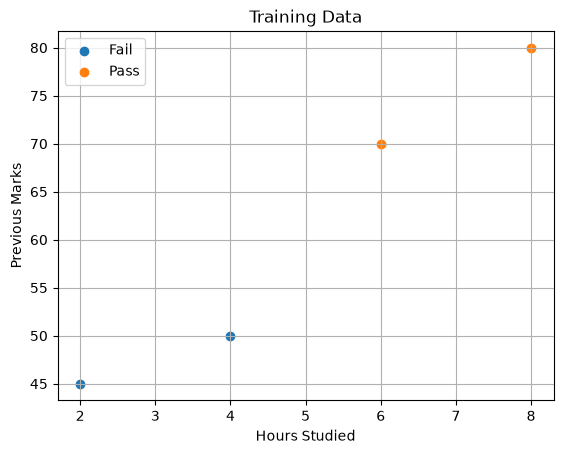

In [48]:
import matplotlib.pyplot as plt

# Feature 1 = Hours studied
# Feature 2 = Previous marks

plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Fail")
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Pass")

plt.xlabel("Hours Studied")
plt.ylabel("Previous Marks")
plt.title("Training Data")
plt.legend()
plt.grid()
plt.show()

## 4. Classification vs Regression

Both are **supervised learning**:

$$X, y \;\rightarrow\; \text{Model learns}$$

But the **type of prediction** is different.

| | Regression | Classification |
|---|---|---|
| **Predicts** | A continuous numerical value | A class / category |
| **Example** | House Price = 250000 | House sold? = 1 |

## 5. Types of Classification

### 🔹 Binary Classification
Two possible classes:

$$y \in \{0, 1\}$$

**Example:**
- `0` → Fail
- `1` → Pass

### 🔹 Multiclass Classification
More than two classes.

$$y \in \{0, 1, 2\}$$

**Example:**
- `0` → Cat
- `1` → Dog
- `2` → Bird

> 📌 For now, in this part of Andrew Ng's course, we are mainly focusing on **binary classification**.

## 6. Important Idea

The model does **not** necessarily produce `0` or `1` immediately.

In **logistic regression**, it first produces a **probability** between 0 and 1:

$$0 \leq f_{w,b}(x) \leq 1$$

Then a **threshold** is used to convert that probability into a class:

$$
P(y=1 \mid x) \geq 0.5 \;\Rightarrow\; 1
$$
$$
P(y=1 \mid x) < 0.5 \;\Rightarrow\; 0
$$

We'll learn exactly how this works with the **sigmoid function**.

# Logistic Regression and the Sigmoid Function

## 1. What is Logistic Regression?

Logistic Regression is a **supervised learning algorithm** used for **classification**.

Classification is the *problem* we are trying to solve, while Logistic Regression is an *algorithm* we can use to solve a binary classification problem.

For example, we may want to predict:

- Pass / Fail
- Yes / No
- Spam / Not Spam
- Disease / No Disease

In binary classification, the target is usually represented as:

$$
y \in \{0, 1\}
$$

So we can think of it as:

$$
\text{Classification = problem} \qquad \text{Logistic Regression = algorithm}
$$

---

## 2. Connection with Linear Regression

In linear regression, we use:

$$
f_{w,b}(x) = wx + b
$$

Here:
- $x$ = input feature  
- $w$ = weight/parameter  
- $b$ = bias  
- $f_{w,b}(x)$ = prediction  

The problem is that $wx + b$ can produce **any** value, such as:

$$
-5,\ 2,\ 10,\ 100
$$

But for classification, we want a value between $0$ and $1$ that can be interpreted as a **probability**.

Therefore, Logistic Regression keeps the linear part but adds the **sigmoid function**.

---

## 3. Sigmoid Function

The sigmoid function is also called the **logistic function**.

Its formula is:

$$
g(z) = \frac{1}{1 + e^{-z}}
$$

It takes any value of $z$ and converts it into a number between $0$ and $1$.

For example:

$$
g(-5) \approx 0.0067 \qquad g(0) = 0.5 \qquad g(5) \approx 0.993
$$

Therefore:

$$
0 < g(z) < 1
$$

The sigmoid is useful because its output can be interpreted as a **probability**.

---

## 4. Logistic Regression Formula

First, we calculate the linear part:

$$
z = wx + b
$$

Then we pass $z$ through the sigmoid function:

$$
f_{w,b}(x) = g(z)
$$

Therefore:

$$
f_{w,b}(x) = g(wx + b)
$$

Substituting the sigmoid formula:

$$
f_{w,b}(x) = \frac{1}{1 + e^{-(wx+b)}}
$$

**Process flow:**

## Logistic Regression Example — Step by Step

In this example, we'll see how **z** is calculated (`z = wx + b`), 
and then how that **z** is passed into the **sigmoid function** to get a probability.

**Data:**
- Each row represents a student's data: `[hours_studied, marks]`
- `y` tells us whether the student **Passed (1)** or **Failed (0)**

### Step 1: Calculate `z = w·x + b`

For each example, we compute the linear combination:

$$
z = w_1x_1 + w_2x_2 + b
$$

Where:
- `w` = weights (importance of each feature)
- `b` = bias
- Since `X` has 2 features (hours, marks), `w` is also an array of 2 values

In [49]:
def compute_z(X, w, b):
    """
    z = X·w + b
    X: shape (m, n)  -> m examples, n features
    w: shape (n,)     -> weights for each feature
    b: scalar         -> bias
    """
    z = np.dot(X, w) + b
    return z

# Weights and bias (chosen manually for this example)
w = np.array([0.5, 0.1])
b = -7

z = compute_z(X, w, b)
print("z values =", z)

z values = [-1.5  0.   3.   5. ]


### Step 2: Apply the Sigmoid Function to get Probability

The values of `z` can range from `-∞` to `+∞`, which cannot represent a probability.

So we use the **sigmoid function** to squeeze every value into a range between `0` and `1`:

$$
g(z) = \frac{1}{1 + e^{-z}}
$$

In [50]:
def sigmoid(z):
    """
    Converts any real number into a value between 0 and 1
    """
    return 1 / (1 + np.exp(-z))

# Apply sigmoid on z
probabilities = sigmoid(z)
print("Probabilities =", probabilities)

Probabilities = [0.18242552 0.5        0.95257413 0.99330715]


### Step 3: Interpreting the Result

Each `z` value has now become a probability (between 0 and 1).

**Decision Rule:**
$$
P(y=1|x) \geq 0.5 \Rightarrow \text{Predict } 1 \ (\text{Pass})
$$
$$
P(y=1|x) < 0.5 \Rightarrow \text{Predict } 0 \ (\text{Fail})
$$

In [51]:
# Apply threshold of 0.5
predictions = (probabilities >= 0.5).astype(int)

for i in range(len(X)):
    print(f"X = {X[i]}  →  z = {z[i]:.2f}  →  probability = {probabilities[i]:.4f}  →  predicted class = {predictions[i]}  (actual = {y[i]})")

X = [ 2 45]  →  z = -1.50  →  probability = 0.1824  →  predicted class = 0  (actual = 0)
X = [ 4 50]  →  z = 0.00  →  probability = 0.5000  →  predicted class = 1  (actual = 0)
X = [ 6 70]  →  z = 3.00  →  probability = 0.9526  →  predicted class = 1  (actual = 1)
X = [ 8 80]  →  z = 5.00  →  probability = 0.9933  →  predicted class = 1  (actual = 1)


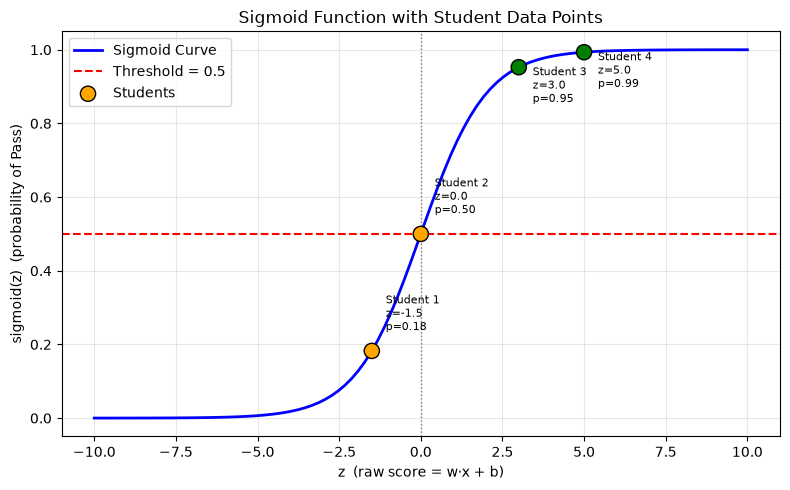

In [52]:
z_range = np.linspace(-10, 10, 100)

plt.figure(figsize=(8, 5))
plt.plot(z_range, sigmoid(z_range), color='blue', linewidth=2, label='Sigmoid Curve')
plt.axhline(0.5, color='red', linestyle='--', label='Threshold = 0.5')
plt.axvline(0, color='gray', linestyle=':', linewidth=1)

# Plot each student's actual z and probability as a dot
colors = ['green' if pred == 1 else 'orange' for pred in y]
plt.scatter(z, probabilities, color=colors, s=120, zorder=5, edgecolor='black', label='Students')

# Label each dot with student number, z, and probability
for i in range(len(z)):
    label = f"Student {i+1}\nz={z[i]:.1f}\np={probabilities[i]:.2f}"
    plt.annotate(label, (z[i], probabilities[i]),
                 textcoords="offset points", xytext=(10, -25 if y[i]==1 else 15),
                 fontsize=8, ha='left')

plt.xlabel('z  (raw score = w·x + b)')
plt.ylabel('sigmoid(z)  (probability of Pass)')
plt.title('Sigmoid Function with Student Data Points')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Understanding the Two Colors in the Plot

In this plot, you can see two colors: **orange** and **green**.

- The **orange dots** represent students whose probability is **near or equal to 0.5** — 
  meaning the model is **not confident** (unsafe / borderline prediction).
- The **green dots** represent students whose probability is **high (close to 1)** — 
  meaning the model is **confident** they will Pass (safe prediction).

If you look back at our original data, the raw feature values (like `[8, 80]` or `[2, 45]`) 
are **very different in scale** from probabilities — they can be small or large numbers 
with no fixed range.

This is exactly **why we use the sigmoid function**: no matter how big or small the input 
`z` is, sigmoid always squeezes it into a clean result **between 0 and 1**, which we can 
then interpret as a probability.

## Threshold vs Decision Boundary — What's the Difference?

People often think **threshold** and **decision boundary** are the same thing. 
They are **related**, but they are **not the same** — each serves a different purpose.

---

### What is the Threshold?

The **threshold** is simply a **cutoff value for probability**.

- It is usually **0.5**, but it can be changed to **0.3**, **0.7**, or any value depending on the problem.
- It works on the **output of the sigmoid function** (a number between 0 and 1).

$$
P(y=1|x) \geq \text{threshold} \Rightarrow \text{predict } 1
$$
$$
P(y=1|x) < \text{threshold} \Rightarrow \text{predict } 0
$$

So the threshold decides: **"At what probability do I switch from predicting 0 to predicting 1?"**

---

### What is the Decision Boundary?

The **decision boundary** is the **line (or curve) in the input space (x)** that separates 
class 0 from class 1.

- While the threshold works on the **probability**, the decision boundary works on the 
  **actual feature values (x)** — the real-world input, like hours studied or marks.
- It answers: **"At what value of x does the prediction switch from 0 to 1?"**

---

### How They Connect

The threshold on probability **directly creates** the decision boundary in the input space.

$$
\text{threshold on } P(y=1|x) \quad \longrightarrow \quad \text{decision boundary on } x
$$

For example, with the default threshold of 0.5:

$$
P(y=1|x) = 0.5 \quad \Rightarrow \quad z = 0 \quad \Rightarrow \quad wx + b = 0
$$

Solving `wx + b = 0` for `x` gives you the **exact point (or line)** in your data 
that separates the two classes — that is the **decision boundary**.

---

### Simple Way to Remember

| Concept | Works On | Answers the Question |
|---|---|---|
| **Threshold** | Probability (0 to 1) | "How confident must the model be before predicting 1?" |
| **Decision Boundary** | Input features (x) | "At what value of x does the prediction switch?" |

So:
- **Threshold** is the cutoff on the **probability axis**.
- **Decision boundary** is where that cutoff **lands on the actual data** (x-axis, or 
  even a 2D plane if you have 2 features).

They are two views of the **same decision** — one in probability space, one in feature space.

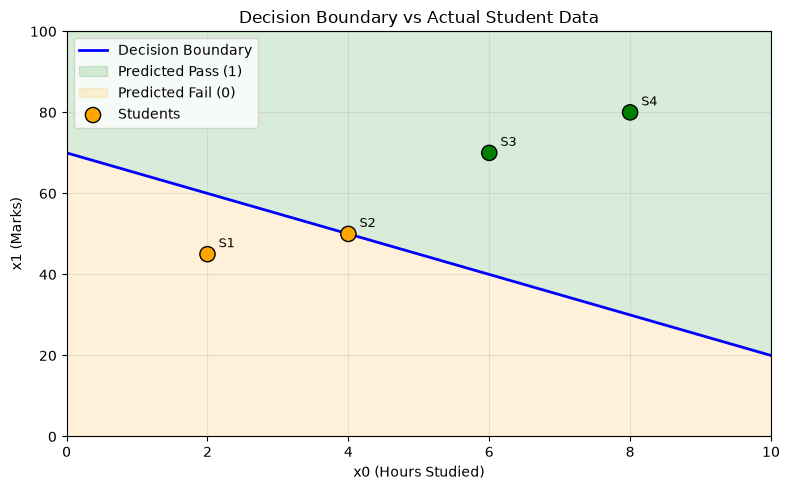

In [53]:
# Decision boundary: x1 = 70 - 5*x0
x0_range = np.linspace(0, 10, 100)
x1_boundary = 70 - 5 * x0_range

plt.figure(figsize=(8, 5))

# Plot the decision boundary line
plt.plot(x0_range, x1_boundary, color='blue', linewidth=2, label='Decision Boundary')

# Fill regions
plt.fill_between(x0_range, x1_boundary, 100, alpha=0.15, color='green', label='Predicted Pass (1)')
plt.fill_between(x0_range, x1_boundary, 0, alpha=0.15, color='orange', label='Predicted Fail (0)')

# Plot actual student data points
colors = ['green' if label == 1 else 'orange' for label in y]
plt.scatter(X[:,0], X[:,1], color=colors, s=120, edgecolor='black', zorder=5, label='Students')

# Label each point
for i in range(len(X)):
    plt.annotate(f"S{i+1}", (X[i,0], X[i,1]), textcoords="offset points", xytext=(8,5), fontsize=9)

plt.xlabel('x0 (Hours Studied)')
plt.ylabel('x1 (Marks)')
plt.title('Decision Boundary vs Actual Student Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 10)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Loss Function

In supervised learning, we use a **cost function** to reduce errors and make predictions more accurate. The same concept applies here, but with a key distinction:

- **Loss function** → calculated **per example** (single training example)
- **Cost function** → calculated as the **average** over all examples

### Loss Function (Logistic Regression)

$$L(f, y) = -\left[y\log(f) + (1-y)\log(1-f)\right]$$

Where:
- $L$ = Loss
- $f$ = Model's prediction (probability)
- $y$ = Actual label, either 0 or 1

This simplifies depending on the value of $y$:

- If $y = 1 \Rightarrow L = -\log(f)$
- If $y = 0 \Rightarrow L = -\log(1-f)$

### Cost Function

For the whole dataset, we average the loss over all $m$ examples:

$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m} L\big(f^{(i)}, y^{(i)}\big)$$

### Summary

| Term | Meaning |
|------|---------|
| **Loss** | Error for **one** training example |
| **Cost** | **Average loss** across **all** training examples |

In [1]:
def compute_cost(w, x, y, b):
    m = x.shape[0]
    cost = 0

    for i in range(m):
        z = np.dot(x[i], w) + b
        f = sigmoid(z)

        loss = -y[i] * np.log(f) - (1 - y[i]) * np.log(1 - f)
        cost += loss

    cost = cost / m
    return cost

In [ ]:
loss = compute_cost(w, X, y, b)
print("Loss per example:", loss)

Loss per example: 0.2374657896513894


# Logistic Regression Cost Function Summary

The computed cost for the current parameters is:

**Cost = 0.2374657896513894**

This value represents the **average loss** across all training examples. In logistic regression, the cost function measures how well the model's predictions match the actual labels.

* A **lower cost** indicates that the model's predictions are closer to the true labels.
* A **higher cost** indicates larger prediction errors.

At this stage, the weights (**w**) and bias (**b**) are fixed, so this cost reflects the model's performance using those specific parameter values.

## What's Next?

In the next section, we will study **Gradient Descent**, which is the optimization algorithm used to **minimize the cost function**.

During each iteration of gradient descent:

1. The gradients of the cost function with respect to **w** and **b** are computed.
2. The values of **w** and **b** are updated in the direction that reduces the cost.
3. The cost is recalculated using the updated parameters.
4. This process repeats until the cost converges to a minimum.

The objective of gradient descent is to find the optimal values of **w** and **b** that produce the **lowest possible cost**, resulting in a model that makes more accurate predictions on unseen data.


Now we will learn the gradient descent , in the linear regression you have heard the term gradient descent this is the same as the linear but there is a small different 